# Laboratorio 4 - Segmentación de imágenes con técnicas de agrupación

*Presentado por:*
- Shaiel Jiménez - 202323846
- Juan Esteban Triviño - 202315338

*ISIS2611 - Aprendizaje de Máquina / Sección 5*

*Profesor: Rubén Manrique*

**Contenido**

- [Introducción](#introduccion)
- [Configuración del entorno](#entorno)
- [Exploración de las imágenes de ajuste](#exploracion)
- [Actividad 1 - Pipeline de preparación y representación](#actividad1)
- [Actividad 2 - Agrupación y selección de K](#actividad2)
- [Actividad 3 - Construcción de la máscara de la lesión](#actividad3)
- [Actividad 4 - Ajuste del método](#actividad4)
- [Actividad 5 - Evaluación en las imágenes de prueba](#actividad5)

## <a id="introduccion"></a> Introducción

DermAlpes es una empresa de telemedicina que conecta centros de salud de municipios pequeños con dermatólogos de las ciudades principales. El personal toma fotografías de las lesiones de piel con un dermatoscopio y las envía para que un especialista las revise a distancia, y la empresa quiere una herramienta que delimite automáticamente la lesión para que el dermatólogo pueda medir su tamaño y forma. Como no cuenta con imágenes etiquetadas de sus pacientes, quiere saber si es posible segmentar la lesión sin entrenar un modelo supervisado, agrupando los píxeles según su color y su posición. La herramienta no hace diagnósticos, solo delimita la lesión.

En este laboratorio se construye ese método sobre 20 imágenes públicas que incluyen máscaras de referencia hechas por especialistas. Cada píxel se representa con su color y su posición, ponderados por β y λ, y se agrupa con K-medias, eligiendo el número de grupos con el coeficiente de silueta. Luego se define un criterio para decidir qué grupos forman la lesión, se ajusta la configuración con 15 imágenes y se evalúa sin cambios en las 5 restantes. Por último se analiza dónde falla el método y qué riesgos tendría usarlo con pacientes, cámaras o condiciones de luz distintas.

## <a id="entorno"></a> Configuración del entorno

In [23]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, v_measure_score, f1_score, precision_score, recall_score

SEMILLA = 42

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1


### Datos

Se usan 20 imágenes dermatoscópicas del conjunto ISIC 2016, tarea de segmentación de lesiones ([enlace](https://challenge.isic-archive.com/landing/2016/37/)), cada una con su máscara de referencia elaborada por especialistas. Siguiendo el enunciado, 15 imágenes son de ajuste y 5 de prueba. Las de prueba y sus máscaras no se abren hasta la Actividad 5, así que aquí solo se comprueba que los archivos existen.

Los datos van en *data/raw/ajuste* y *data/raw/prueba*, con los nombres originales (*ISIC_0000085.jpg* y *ISIC_0000085_Segmentation.png*). Las rutas se arman con *pathlib* y son relativas a la carpeta del notebook, para que funcionen igual en macOS, Linux o Windows.

In [24]:
DATA_DIR = Path("data") / "raw"

IDS_AJUSTE = ["ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094", "ISIC_0000108",
              "ISIC_0000114", "ISIC_0000116", "ISIC_0000122", "ISIC_0000133", "ISIC_0000137",
              "ISIC_0000150", "ISIC_0000153", "ISIC_0000156", "ISIC_0000157", "ISIC_0000112"]
IDS_PRUEBA = ["ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123", "ISIC_0000128"]

def carpeta(id_img):
    return DATA_DIR / ("prueba" if id_img in IDS_PRUEBA else "ajuste")

def ruta_imagen(id_img):
    return carpeta(id_img) / f"{id_img}.jpg"

def ruta_mascara(id_img):
    return carpeta(id_img) / f"{id_img}_Segmentation.png"

# Solo se verifica que existan los archivos, sin abrirlos
todos = IDS_AJUSTE + IDS_PRUEBA
faltantes = [str(r) for i in todos for r in (ruta_imagen(i), ruta_mascara(i)) if not r.exists()]
print(f"IDs: {len(IDS_AJUSTE)} de ajuste + {len(IDS_PRUEBA)} de prueba = {len(set(todos))}")
print(f"Archivos esperados: {2 * len(todos)} | faltantes: {len(faltantes)} {faltantes if faltantes else ''}")
print("IDs en ajuste y prueba a la vez:", set(IDS_AJUSTE) & set(IDS_PRUEBA))

IDs: 15 de ajuste + 5 de prueba = 20
Archivos esperados: 40 | faltantes: 0 
IDs en ajuste y prueba a la vez: set()


## <a id="exploracion"></a> Exploración de las imágenes de ajuste

### Carga y verificación

Se cargan las 15 imágenes de ajuste con sus máscaras y se revisa lo que el enunciado da por hecho: que cada máscara tiene el mismo tamaño que su imagen y solo los valores 0 (piel o fondo) y 255 (lesión).

In [25]:
def cargar(id_img):
    img = np.array(Image.open(ruta_imagen(id_img)).convert("RGB"))
    mascara = np.array(Image.open(ruta_mascara(id_img)))
    return img, mascara

originales = {i: cargar(i) for i in IDS_AJUSTE}

filas = []
for id_img, (img, mascara) in originales.items():
    assert img.shape[:2] == mascara.shape, f"{id_img}: tamaños distintos"
    filas.append({"id": id_img, "alto": img.shape[0], "ancho": img.shape[1],
                  "ancho/alto": round(img.shape[1] / img.shape[0], 2),
                  "valores máscara": sorted(np.unique(mascara).tolist()),
                  "% lesión": round((mascara > 127).mean() * 100, 1)})
resumen_ajuste = pd.DataFrame(filas).set_index("id")
resumen_ajuste

,alto,ancho,ancho/alto,valores máscara,% lesión
id,,,,,
ISIC_0000085,1536,2048,1.33,"[0, 255]",12.7
ISIC_0000086,1944,2592,1.33,"[0, 255]",23.4
ISIC_0000089,1536,2048,1.33,"[0, 255]",12.1
ISIC_0000094,1536,2048,1.33,"[0, 255]",5.9
ISIC_0000108,1536,2048,1.33,"[0, 255]",18.5
ISIC_0000114,1536,2048,1.33,"[0, 255]",3.1
ISIC_0000116,1536,2048,1.33,"[0, 255]",36.1
ISIC_0000122,1536,2048,1.33,"[0, 255]",39.0
ISIC_0000133,1536,2048,1.33,"[0, 255]",14.2


**Hallazgos.** Las 15 máscaras son binarias y coinciden en tamaño con su imagen, así que no requieren corrección. Casi todas las imágenes miden 2048 x 1536 píxeles; dos son más grandes (086 y 153) y una más pequeña y menos ancha (157). La lesión ocupa entre el 3.1% y el 39% de la imagen (mediana de 23.4%), de modo que un criterio basado en el tamaño del grupo no sería confiable. Con imágenes de más de tres millones de píxeles, agrupar a resolución completa sería muy costoso, por eso más adelante se reducen.

### Vista general

K-medias solo ve el color y la posición de cada píxel, así que cualquier cosa con un color parecido al de la lesión, como pelos, bordes oscuros del lente o marcas, puede terminar en su mismo grupo. Se muestran las 15 imágenes con el contorno de la máscara de referencia para ver qué casos tendrá que enfrentar el método.

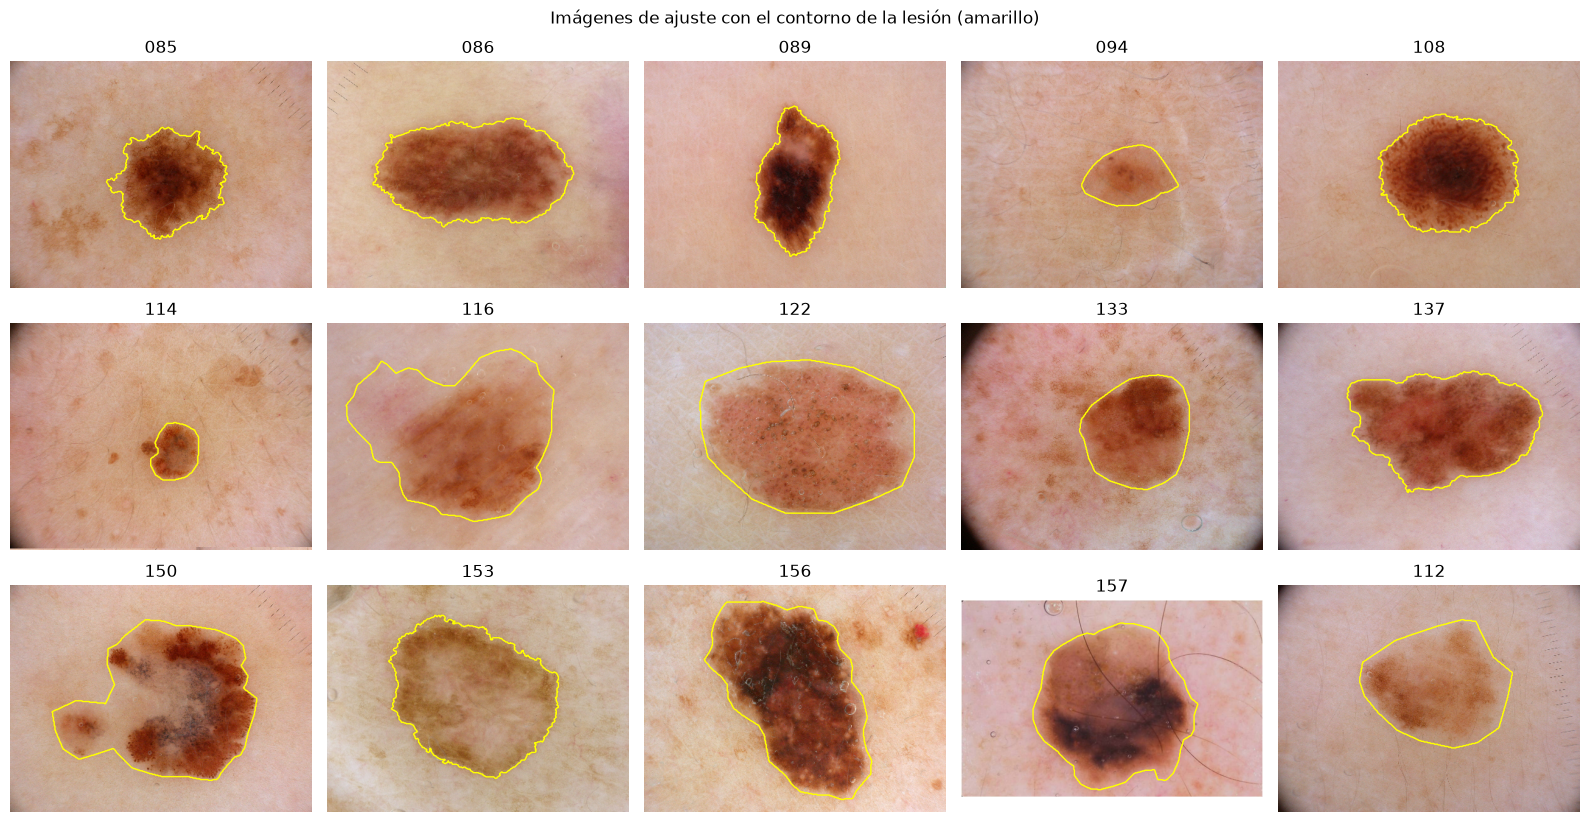

In [26]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8.5))
for ax, (id_img, (img, mascara)) in zip(axes.ravel(), originales.items()):
    paso = max(1, img.shape[1] // 400)  # se submuestrea solo para dibujar
    ax.imshow(img[::paso, ::paso])
    ax.contour(mascara[::paso, ::paso], levels=[127], colors="yellow", linewidths=1)
    ax.set_title(id_img[-3:])
    ax.axis("off")
plt.suptitle("Imágenes de ajuste con el contorno de la lesión (amarillo)")
plt.tight_layout()
plt.show()

**Hallazgos.** En casi todas las imágenes la lesión es café, más oscura que la piel y está cerca del centro, que son las condiciones que favorecen a un método basado en color y posición. Aun así aparecen varios casos difíciles. En 133 las esquinas son negras por el lente, y en 112, 114 y 137 se oscurecen un poco, lo que puede confundirse con la lesión. Varias imágenes tienen una regla o marcas de medida en el borde (por ejemplo 085, 133, 137, 150 y 156), y en 157 hay pelos gruesos que cruzan la lesión. Algunas lesiones tienen poco contraste con la piel o son muy claras (094, 112 y parte de 116), y otras combinan zonas oscuras y claras (089, 150, 153 y 157), así que la lesión podría quedar repartida en más de un grupo. También hay pecas o manchas fuera de la lesión (085, 114 y 133) y un punto rojo en 156. Por último, algunas máscaras de referencia tienen un contorno suave y redondeado (094, 112, 116 y 122), con lo que parte de la piel cercana queda dentro de la lesión de referencia, mientras que otras siguen el borde con detalle.

### Cómo es la lesión frente a la piel

Antes de proponer un criterio para reconocer la lesión conviene medir si de verdad es más oscura que la piel y si suele estar en el centro. Para cada imagen se calcula la ubicación del centro de la lesión (en coordenadas de 0 a 1), su distancia al centro de la imagen, si toca el borde, la luminosidad media (promedio de R, G y B entre 0 y 1) de la lesión y de la piel, y la distancia de color entre ambas. Las máscaras solo se usan aquí para describir, no para agrupar.

In [27]:
def describir(img, mascara, paso=4):
    img = img[::paso, ::paso] / 255.0  # submuestreo para no recorrer millones de píxeles
    lesion = mascara[::paso, ::paso] > 127
    alto, ancho = lesion.shape
    filas, columnas = np.nonzero(lesion)
    cx, cy = columnas.mean() / (ancho - 1), filas.mean() / (alto - 1)
    color_lesion, color_piel = img[lesion].mean(axis=0), img[~lesion].mean(axis=0)
    return {"centro x": cx, "centro y": cy,
            "dist. al centro": np.hypot(cx - 0.5, cy - 0.5),
            "toca borde": bool(lesion[0].any() or lesion[-1].any() or lesion[:, 0].any() or lesion[:, -1].any()),
            "lum. lesión": color_lesion.mean(), "lum. piel": color_piel.mean(),
            "dist. color": np.linalg.norm(color_lesion - color_piel)}

descriptivos = pd.DataFrame([describir(*originales[i]) for i in IDS_AJUSTE], index=IDS_AJUSTE)
descriptivos.insert(0, "% lesión", resumen_ajuste["% lesión"])
display(descriptivos.round(2))
descriptivos.drop(columns="toca borde").describe().loc[["min", "50%", "max"]].round(2)

,% lesión,centro x,centro y,dist. al centro,toca borde,lum. lesión,lum. piel,dist. color
ISIC_0000085,12.7,0.53,0.53,0.04,False,0.33,0.63,0.54
ISIC_0000086,23.4,0.49,0.49,0.02,False,0.39,0.70,0.56
ISIC_0000089,12.1,0.51,0.53,0.03,False,0.29,0.71,0.72
ISIC_0000094,5.9,0.56,0.51,0.06,False,0.50,0.66,0.31
ISIC_0000108,18.5,0.57,0.50,0.07,False,0.32,0.65,0.59
ISIC_0000114,3.1,0.55,0.57,0.09,False,0.40,0.64,0.45
ISIC_0000116,36.1,0.44,0.49,0.06,False,0.52,0.69,0.32
ISIC_0000122,39.0,0.54,0.49,0.04,False,0.52,0.70,0.36
ISIC_0000133,14.2,0.59,0.48,0.09,False,0.39,0.60,0.39
ISIC_0000137,24.5,0.55,0.45,0.07,False,0.38,0.71,0.60


,% lesión,centro x,centro y,dist. al centro,lum. lesión,lum. piel,dist. color
min,3.1,0.44,0.44,0.02,0.29,0.60,0.24
50%,23.4,0.53,0.49,0.04,0.40,0.70,0.48
max,39.0,0.59,0.57,0.09,0.53,0.74,0.72


**Hallazgos.** En las 15 imágenes de ajuste la lesión es más oscura que la piel (luminosidad de 0.29 a 0.53 frente a 0.60 a 0.74), está muy cerca del centro (su centro queda a 0.09 o menos del centro de la imagen) y no toca el borde. Esto respalda dos ideas para reconocer el grupo de la lesión: que sea el más oscuro y que esté hacia el centro. La distancia de color entre lesión y piel va de 0.24 a 0.72 (mediana 0.48), y las de menor contraste son 112, 094 y 116, que ya se veían difíciles en la vista general. Son solo 15 imágenes, así que estas regularidades describen este conjunto y no tienen por qué cumplirse con otras fotos.

### Resolución de trabajo

Cada píxel es una fila de datos, y con más de tres millones de píxeles por imagen agrupar y calcular la silueta sería muy lento (la silueta crece con el cuadrado del número de puntos). Por eso cada imagen se reduce conservando su proporción: la imagen con interpolación bilineal y la máscara con vecino más cercano, para que siga teniendo solo ceros y unos. Como las coordenadas se normalizan entre 0 y 1, λ significa lo mismo a cualquier resolución.

Para elegir el tamaño se mide cuánto detalle del contorno se pierde: cada máscara se reduce, se vuelve a ampliar y se compara con la original mediante el coeficiente de Dice. Se fijó de antemano usar 128 píxeles de lado mayor si el Dice medio es al menos 0.98, y 192 si no.

In [28]:
def reducir(img, mascara, lado):
    escala = lado / max(img.shape[:2])
    tamano = (round(img.shape[1] * escala), round(img.shape[0] * escala))  # Pillow usa (ancho, alto)
    img_r = np.array(Image.fromarray(img).resize(tamano, Image.BILINEAR))
    mascara_r = np.array(Image.fromarray(mascara).resize(tamano, Image.NEAREST))
    return img_r, (mascara_r > 127).astype(np.uint8)

def dice(a, b):
    # Igual a f1_score con la lesión como clase positiva, pero más rápido a resolución completa
    a, b = a.astype(bool), b.astype(bool)
    return 2 * (a & b).sum() / (a.sum() + b.sum())

techo = {}
for lado in [96, 128, 192, 256]:
    valores = []
    for img, mascara in originales.values():
        _, chica = reducir(img, mascara, lado)
        ampliada = np.array(Image.fromarray(chica).resize(mascara.shape[::-1], Image.NEAREST))
        valores.append(dice(ampliada, mascara > 127))
    techo[lado] = {"Dice medio": np.mean(valores), "Dice mínimo": np.min(valores)}
pd.DataFrame(techo).T.rename_axis("lado mayor (px)").round(4)

,Dice medio,Dice mínimo
lado mayor (px),,
96,0.9851,0.9702
128,0.9885,0.9746
192,0.9922,0.9824
256,0.9940,0.9877


**Hallazgos.** Al reducir a 128 píxeles de lado mayor, la máscara conserva casi todo su contorno (Dice medio de 0.9885 y mínimo de 0.9746 frente a la original), y pasar a 192 o 256 solo mejora en milésimas. Se trabaja a 128 píxeles, que deja unos 12 mil píxeles por imagen, y esa resolución se mantiene igual para todas las configuraciones y para la prueba. Esto también marca un techo: aunque el método acertara perfectamente, su Dice no podría superar ese valor por la pérdida de detalle en el borde.

## <a id="actividad1"></a> Actividad 1 - Pipeline de preparación y representación

### Imágenes reducidas y máscaras de 0 y 1

Cada imagen de ajuste se reduce a 128 píxeles de lado mayor y su máscara pasa de 0 y 255 a 0 y 1, donde 1 es la lesión, como pide el enunciado.

In [29]:
LADO = 128
datos_ajuste = {i: reducir(*originales[i], LADO) for i in IDS_AJUSTE}

tamanos = pd.Series({i: img.shape[:2] for i, (img, _) in datos_ajuste.items()}).value_counts()
print("Tamaños reducidos (alto, ancho):", tamanos.to_dict())
print("Valores de las máscaras:", sorted(set(np.concatenate([m.ravel() for _, m in datos_ajuste.values()]).tolist())))

Tamaños reducidos (alto, ancho): {(96, 128): 14, (84, 128): 1}
Valores de las máscaras: [0, 1]


### De la imagen a una matriz de píxeles

Cada imagen se convierte en una matriz con una fila por píxel y cinco columnas: R, G y B divididos entre 255, y las coordenadas x (columna) e y (fila) divididas entre el ancho y el alto menos uno. Así las cinco columnas quedan entre 0 y 1. Esto importa porque K-medias agrupa por distancias, y si el color fuera de 0 a 255 y la posición de 0 a 128, el color pesaría más solo por su escala. El orden de las filas es el mismo de la máscara aplanada, lo que permite comparar luego cada píxel con su etiqueta de referencia.

In [30]:
def imagen_a_matriz(img):
    alto, ancho = img.shape[:2]
    filas, columnas = np.mgrid[0:alto, 0:ancho]
    color = img.reshape(-1, 3) / 255.0
    x = columnas.ravel() / (ancho - 1)
    y = filas.ravel() / (alto - 1)
    return np.column_stack([color, x, y])

img, mascara = datos_ajuste["ISIC_0000085"]
X = imagen_a_matriz(img)
print("Forma:", X.shape, "| píxeles de la imagen:", img.shape[0] * img.shape[1])
pd.DataFrame({"mínimo": X.min(axis=0), "máximo": X.max(axis=0)}, index=["R", "G", "B", "x", "y"]).round(3)

Forma: (12288, 5) | píxeles de la imagen: 12288


,mínimo,máximo
R,0.251,0.839
G,0.047,0.710
B,0.008,0.706
x,0.000,1.000
y,0.000,1.000


### Pesos β y λ

El transformador *PesosBetaLambda* multiplica las columnas de color por β y las de posición por λ. Como β y λ son parámetros del transformador, se pueden cambiar con *set_params* sin tocar el código. No aprende nada de los datos, por eso *fit* solo devuelve el mismo objeto.

Con estos pesos, la distancia al cuadrado entre dos píxeles queda β² · (distancia de color² + (λ/β)² · distancia de posición²). El factor β² multiplica todas las distancias por igual, así que no cambia qué centroide queda más cerca de cada píxel: lo único que cuenta es la razón λ/β. Con λ = 0 solo se usa el color y con β = 0 solo la posición.

In [31]:
class PesosBetaLambda(BaseEstimator, TransformerMixin):
    def __init__(self, beta=1.0, lam=0.0):
        self.beta = beta
        self.lam = lam

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X * np.array([self.beta] * 3 + [self.lam] * 2)

pesos = PesosBetaLambda(beta=2, lam=0.5)
print("Máximo por columna con beta=2 y lam=0.5:", pesos.fit_transform(X).max(axis=0).round(3))
print("Máximo por columna con beta=0 (solo posición):", pesos.set_params(beta=0, lam=1).transform(X).max(axis=0).round(3))

Máximo por columna con beta=2 y lam=0.5: [1.678 1.42  1.412 0.5   0.5  ]
Máximo por columna con beta=0 (solo posición): [0. 0. 0. 1. 1.]


### Pipeline completo

El pipeline encadena los tres pasos: convertir la imagen en matriz, aplicar los pesos y agrupar con K-medias. Cada imagen se agrupa por separado, porque sus colores y su iluminación son propios, y β, λ y K se cambian con *set_params*. K-medias usa 10 inicializaciones (*n_init*) y la semilla fija, porque solo garantiza un mínimo local y el resultado depende de dónde empiece.

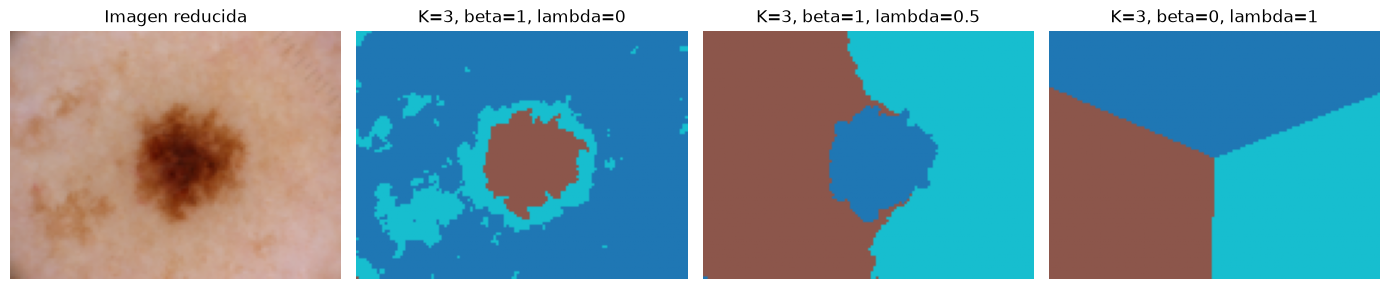

In [32]:
pipeline = Pipeline([
    ("pixeles", FunctionTransformer(imagen_a_matriz)),
    ("pesos", PesosBetaLambda()),
    ("kmeans", KMeans(n_init=10, random_state=SEMILLA)),
])

def agrupar(img, beta, lam, k):
    pipeline.set_params(pesos__beta=beta, pesos__lam=lam, kmeans__n_clusters=k).fit(img)
    return pipeline.named_steps["kmeans"].labels_.reshape(img.shape[:2])

img, mascara = datos_ajuste["ISIC_0000085"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].imshow(img)
axes[0].set_title("Imagen reducida")
for ax, (beta, lam) in zip(axes[1:], [(1, 0), (1, 0.5), (0, 1)]):
    ax.imshow(agrupar(img, beta, lam, 3), cmap="tab10")
    ax.set_title(f"K=3, beta={beta}, lambda={lam}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Solo importa la razón λ/β

Si se multiplican β y λ por la misma constante, todas las distancias se multiplican por igual y K-medias forma los mismos grupos. Se comprueba con el ejemplo del enunciado, (β = 1, λ = 0.5) frente a (β = 2, λ = 1).

In [33]:
grupos_1 = agrupar(img, 1, 0.5, 3)
grupos_2 = agrupar(img, 2, 1, 3)
print("Mismos grupos con (1, 0.5) y (2, 1):", np.array_equal(grupos_1, grupos_2))

Mismos grupos con (1, 0.5) y (2, 1): True


### Alineación entre la matriz y la máscara

Si el orden de las filas de la matriz no coincidiera con el de la máscara aplanada, el Dice saldría mal sin que nada avisara. Se reconstruye la imagen desde la matriz y se comprueba que el centro de la lesión calculado con la matriz coincide con el de la máscara.

In [34]:
X = imagen_a_matriz(img)
reconstruida = (X[:, :3] * 255).reshape(img.shape)
lesion = mascara.ravel() == 1
filas, columnas = np.nonzero(mascara)

print("Imagen reconstruida igual a la original:", np.allclose(reconstruida, img))
print("Centro de la lesión (x, y) desde la matriz:", X[lesion, 3:].mean(axis=0).round(4))
print("Centro de la lesión (x, y) desde la máscara:",
      np.round([columnas.mean() / (img.shape[1] - 1), filas.mean() / (img.shape[0] - 1)], 4))

Imagen reconstruida igual a la original: True
Centro de la lesión (x, y) desde la matriz: [0.5261 0.5325]
Centro de la lesión (x, y) desde la máscara: [0.5261 0.5325]


## <a id="actividad2"></a> Actividad 2 - Agrupación y selección de K

### Las diez combinaciones de β y λ

Como solo importa la razón λ/β, se fija β = 1 y se varía λ, salvo en la combinación de solo posición (β = 0). Las razones se eligieron antes de ver resultados, con más puntos entre 0 y 1, que es donde se espera el paso de "manda el color" a "manda la posición". Aparte se incluye λ/β = 0.2, la razón que recomendó la IA en la actividad de verificación, que se usa solo para evaluar esa recomendación.

In [35]:
COMBINACIONES = {
    "M01": (1, 0), "M02": (1, 0.05), "M03": (1, 0.1), "M04": (1, 0.25), "M05": (1, 0.5),
    "M06": (1, 0.75), "M07": (1, 1), "M08": (1, 2), "M09": (1, 4), "M10": (0, 1),
}
RAZON_IAG = {"IAG": (1, 0.2)}  # recomendación de la IA (ver sección de IA generativa)

tabla_combinaciones = pd.DataFrame(
    [{"beta": b, "lambda": l, "lambda/beta": (l / b if b else np.inf)} for b, l in COMBINACIONES.values()],
    index=list(COMBINACIONES))
tabla_combinaciones

,beta,lambda,lambda/beta
M01,1,0.00,0.00
M02,1,0.05,0.05
M03,1,0.10,0.10
M04,1,0.25,0.25
M05,1,0.50,0.50
M06,1,0.75,0.75
M07,1,1.00,1.00
M08,1,2.00,2.00
M09,1,4.00,4.00
M10,0,1.00,inf


### Muestra para el coeficiente de silueta

La silueta compara, para cada píxel, su distancia media a los píxeles de su grupo con la distancia media al grupo vecino más cercano. Va de -1 a 1, y un valor alto indica grupos compactos y bien separados. Como necesita las distancias entre todos los pares de puntos, su costo crece con el cuadrado de su número, así que se calcula sobre una muestra de píxeles. Se usan 3000 píxeles sin reemplazo con la semilla 42, y la misma muestra para todos los K y combinaciones de una imagen, para que sus siluetas sean comparables. K-medias sí se ajusta con todos los píxeles.

Antes de fijarla se revisa que sea estable: en tres imágenes de ajuste se elige K con muestras de 1000, 3000 y 5000 píxeles y con tres semillas distintas, usando λ/β = 0.5.

In [36]:
MUESTRA = 3000

def indices_muestra(n_pixeles, tamano=MUESTRA, semilla=SEMILLA):
    return np.random.default_rng(semilla).choice(n_pixeles, size=min(tamano, n_pixeles), replace=False)

def k_por_silueta(X, etiquetas_por_k, idx):
    siluetas = {k: silhouette_score(X[idx], etq.ravel()[idx]) for k, etq in etiquetas_por_k.items()}
    return max(siluetas, key=siluetas.get), siluetas

filas = []
for id_img in ["ISIC_0000085", "ISIC_0000116", "ISIC_0000157"]:
    img = datos_ajuste[id_img][0]
    X = PesosBetaLambda(1, 0.5).transform(imagen_a_matriz(img))
    etiquetas_por_k = {k: agrupar(img, 1, 0.5, k) for k in range(2, 9)}
    for tamano in [1000, 3000, 5000]:
        for semilla in [1, 2, 3]:
            k, _ = k_por_silueta(X, etiquetas_por_k, indices_muestra(len(X), tamano, semilla))
            filas.append({"imagen": id_img, "muestra": tamano, "semilla": semilla, "K elegido": k})

estabilidad = pd.DataFrame(filas).pivot_table(index=["imagen", "muestra"], columns="semilla", values="K elegido").astype(int)
estabilidad

semilla               1  2  3
imagen       muestra         
ISIC_0000085 1000     2  2  2
             3000     2  2  2
             5000     2  2  2
ISIC_0000116 1000     5  5  5
             3000     5  5  5
             5000     5  5  5
ISIC_0000157 1000     2  2  2
             3000     2  2  2
             5000     2  2  2

**Hallazgos.** El K elegido por la silueta fue el mismo con muestras de 1000, 3000 y 5000 píxeles y con las tres semillas en las tres imágenes, así que una muestra de 3000 píxeles con semilla 42 basta para elegir K de forma estable. Ya aquí se ve que la silueta suele preferir pocos grupos: en 085 y 157 elige K = 2.

### Agrupación de las 15 imágenes

Para cada imagen de ajuste, cada razón λ/β (las diez y la de la IA) y cada K entre 2 y 8 se agrupa con todos los píxeles y se calcula la silueta sobre la muestra. Se guardan las etiquetas de todos los K y no solo las del elegido, porque la Actividad 3 las necesita para construir las máscaras y el análisis compara K, silueta y Dice. La silueta se calcula sobre los datos ya ponderados, que son los que ve K-medias, por eso solo se compara entre valores de K de una misma razón y no entre razones.

Primero se mide cuánto tarda una imagen para estimar el tiempo total.

In [37]:
RAZONES = {**COMBINACIONES, **RAZON_IAG}
VALORES_K = range(2, 9)

def barrer_imagen(img):
    X = imagen_a_matriz(img)
    idx = indices_muestra(len(X))
    etiquetas, filas = {}, []
    for nombre, (beta, lam) in RAZONES.items():
        X_pesos = PesosBetaLambda(beta, lam).transform(X)
        for k in VALORES_K:
            etq = agrupar(img, beta, lam, k)
            etiquetas[(nombre, k)] = etq.astype(np.int8)
            filas.append({"razón": nombre, "K": k, "silueta": silhouette_score(X_pesos[idx], etq.ravel()[idx])})
    return etiquetas, filas

inicio = perf_counter()
barrer_imagen(datos_ajuste["ISIC_0000085"][0])
segundos = perf_counter() - inicio
print(f"Una imagen: {segundos:.1f} s | estimado para las 15: {segundos * 15 / 60:.1f} min")

Una imagen: 7.3 s | estimado para las 15: 1.8 min


In [38]:
etiquetas = {}
filas = []
for id_img in IDS_AJUSTE:
    etq_img, filas_img = barrer_imagen(datos_ajuste[id_img][0])
    etiquetas.update({(id_img, *clave): etq for clave, etq in etq_img.items()})
    filas += [{"imagen": id_img, **fila} for fila in filas_img]
siluetas = pd.DataFrame(filas)

print("Agrupaciones:", len(etiquetas), "| siluetas calculadas:", siluetas["silueta"].notna().sum())
siluetas.head()

Agrupaciones: 1155 | siluetas calculadas: 1155


,imagen,razón,K,silueta
0,ISIC_0000085,M01,2,0.803261
1,ISIC_0000085,M01,3,0.583875
2,ISIC_0000085,M01,4,0.484290
3,ISIC_0000085,M01,5,0.454382
4,ISIC_0000085,M01,6,0.415131


### Selección de K por silueta

Para cada imagen y razón se elige el K con mayor silueta (si hay empate, el menor). La silueta no usa las máscaras de referencia, así que esta elección se puede repetir igual en una imagen nueva, y por eso K se vuelve a elegir de la misma forma en las imágenes de prueba.

In [39]:
mejor = siluetas.loc[siluetas.groupby(["imagen", "razón"])["silueta"].idxmax()]  # idxmax toma el primero, es decir el K menor
k_elegido = mejor.pivot(index="imagen", columns="razón", values="K")[list(RAZONES)]

print("Veces que se eligió cada K, por razón:")
display(mejor.pivot_table(index="K", columns="razón", values="imagen", aggfunc="count", fill_value=0)[list(RAZONES)])
k_elegido

Veces que se eligió cada K, por razón:


razón,M01,M02,M03,M04,M05,M06,M07,M08,M09,M10,IAG
K,,,,,,,,,,,
2,15,15,15,14,9,2,0,0,0,0,14
4,0,0,0,0,0,0,0,2,6,15,1
5,0,0,0,1,6,12,14,12,9,0,0
6,0,0,0,0,0,1,1,1,0,0,0


razón,M01,M02,M03,M04,M05,M06,M07,M08,M09,M10,IAG
imagen,,,,,,,,,,,
ISIC_0000085,2,2,2,2,2,5,5,5,5,4,2
ISIC_0000086,2,2,2,2,2,5,5,5,5,4,2
ISIC_0000089,2,2,2,2,2,2,5,5,5,4,2
ISIC_0000094,2,2,2,5,5,5,5,4,4,4,4
ISIC_0000108,2,2,2,2,2,5,5,5,5,4,2
ISIC_0000112,2,2,2,2,5,5,5,5,4,4,2
ISIC_0000114,2,2,2,2,5,5,5,4,4,4,2
ISIC_0000116,2,2,2,2,5,5,5,5,5,4,2
ISIC_0000122,2,2,2,2,5,5,5,5,4,4,2


### Curvas de silueta

La forma de la curva dice más que su máximo: un pico claro indica un número natural de grupos, y una caída suave indica poca estructura. Se muestran tres imágenes con solo color, λ/β = 0.5 y solo posición.

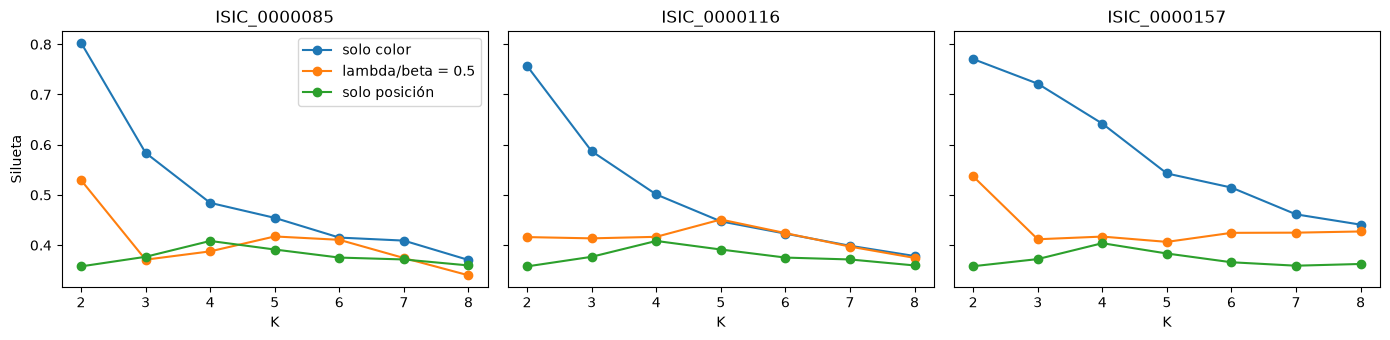

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, id_img in zip(axes, ["ISIC_0000085", "ISIC_0000116", "ISIC_0000157"]):
    for razon, etiqueta in [("M01", "solo color"), ("M05", "lambda/beta = 0.5"), ("M10", "solo posición")]:
        curva = siluetas.query("imagen == @id_img and `razón` == @razon")
        ax.plot(curva["K"], curva["silueta"], marker="o", label=etiqueta)
    ax.set_title(id_img)
    ax.set_xlabel("K")
axes[0].set_ylabel("Silueta")
axes[0].legend()
plt.tight_layout()
plt.show()

**Hallazgos.** La silueta casi siempre elige dos grupos cuando manda el color: con solo color y con λ/β de 0.05 a 0.25 elige K = 2 en 14 o 15 de las 15 imágenes, y sus curvas tienen un pico claro en K = 2. Al aumentar el peso de la posición el K elegido sube a 4 o 5, porque la imagen se parte en regiones geométricas y la silueta mejora con más bloques, aunque las curvas se vuelven casi planas. Con solo posición elige K = 4 en todas las imágenes, como se esperaba, ya que sin color la partición no depende del contenido. Esto muestra que la silueta busca grupos compactos y separados, no la lesión, y que con mucho peso en la posición deja de ser un criterio informativo. Las siluetas solo se comparan entre valores de K de una misma razón, porque cada razón cambia las distancias.

## <a id="actividad3"></a> Actividad 3 - Construcción de la máscara de la lesión

### Descriptores de cada grupo

K-medias entrega etiquetas sin significado: el grupo 0 de una imagen no tiene nada que ver con el grupo 0 de otra. Para decidir cuál es la lesión, cada grupo se describe con su tamaño (fracción de píxeles), su luminosidad media, su distancia media al centro de la imagen y la fracción de sus píxeles que cae en la franja del borde (el 10% exterior). Se calculan con el color y la posición originales, sin pesos, para que sirvan con cualquier razón, incluida la de solo posición, y no usan la máscara de referencia.

In [41]:
def descriptores_grupos(img, etq):
    X = imagen_a_matriz(img)
    x, y = X[:, 3], X[:, 4]
    pixeles = pd.DataFrame({
        "grupo": etq.ravel(),
        "luminosidad": X[:, :3].mean(axis=1),
        "dist. al centro": np.hypot(x - 0.5, y - 0.5),
        "en borde": (x < 0.1) | (x > 0.9) | (y < 0.1) | (y > 0.9),
    })
    tabla = pixeles.groupby("grupo").mean()
    tabla.insert(0, "tamaño", pixeles["grupo"].value_counts(normalize=True).sort_index())
    return tabla

id_img = "ISIC_0000133"
k = k_elegido.loc[id_img, "M05"]
descriptores_grupos(datos_ajuste[id_img][0], etiquetas[(id_img, "M05", k)]).round(3)

,tamaño,luminosidad,dist. al centro,en borde
grupo,,,,
0,0.833,0.623,0.407,0.390
1,0.167,0.339,0.282,0.265


### ¿Qué grupo corresponde a la lesión?

Antes de fijar un criterio se revisa, con las máscaras de las imágenes de ajuste, qué rasgos tiene el grupo que mejor coincide con la lesión. Para cada imagen y razón, con su K elegido, se calcula el Dice de cada grupo por separado contra la máscara de referencia y se marca el mejor. Luego se cuenta en cuántas imágenes ese grupo es también el más oscuro, el más cercano al centro o el que menos toca el borde. Esto usa las máscaras de ajuste solo para diseñar el criterio, lo que el protocolo permite; el criterio final usará únicamente los descriptores, así que podrá aplicarse a una imagen sin máscara.

In [42]:
filas = []
for id_img in IDS_AJUSTE:
    img, mascara = datos_ajuste[id_img]
    for razon in RAZONES:
        etq = etiquetas[(id_img, razon, k_elegido.loc[id_img, razon])]
        desc = descriptores_grupos(img, etq)
        dice_grupo = {g: dice(etq == g, mascara) for g in desc.index}
        mejor_grupo = max(dice_grupo, key=dice_grupo.get)
        filas.append({"imagen": id_img, "razón": razon, "Dice del mejor grupo": dice_grupo[mejor_grupo],
                      "es el más oscuro": mejor_grupo == desc["luminosidad"].idxmin(),
                      "es el más central": mejor_grupo == desc["dist. al centro"].idxmin(),
                      "es el que menos toca el borde": mejor_grupo == desc["en borde"].idxmin()})
diagnostico = pd.DataFrame(filas)

resumen_diagnostico = diagnostico.groupby("razón", sort=False).agg(
    {"Dice del mejor grupo": "mean", "es el más oscuro": "sum", "es el más central": "sum", "es el que menos toca el borde": "sum"})
resumen_diagnostico.round(3)

,Dice del mejor grupo,es el más oscuro,es el más central,es el que menos toca el borde
razón,,,,
M01,0.848,15,15,14
M02,0.848,15,15,14
M03,0.848,15,15,14
M04,0.853,15,15,14
M05,0.861,15,15,15
M06,0.864,14,15,15
M07,0.830,14,15,15
M08,0.735,15,14,14
M09,0.588,13,12,12


**Hallazgos.** Cuando el color tiene peso (λ/β de 0 a 1), el grupo que mejor coincide con la lesión es casi siempre el más oscuro y el más cercano al centro, lo que respalda usar esas dos propiedades para reconocerlo. Las excepciones muestran sus límites: en 133, con λ/β de 0.75 y 1, el grupo más oscuro son las esquinas negras del lente y no la lesión, mientras que el más central sí acierta; y en 114, cuya lesión ocupa solo el 3% de la imagen, el mejor grupo apenas llega a un Dice de 0.59 porque con dos grupos la lesión queda junto a otras manchas. El Dice del mejor grupo es además un techo para cualquier criterio que elija un solo grupo: ronda 0.85 cuando manda el color, cae a 0.59 con λ/β = 4 y a 0.30 con solo posición, donde los grupos ya no siguen la lesión.

### Criterios para construir la máscara

Se comparan tres criterios, definidos antes de evaluarlos y sin ajustar nada después:

- **CA, el grupo más oscuro.** El más simple, y en el diagnóstico anterior coincide casi siempre con la lesión.
- **CB, el grupo más oscuro y central.** Elige el grupo con menor suma de luminosidad y distancia al centro, con pesos iguales (las dos van en escalas parecidas, de 0 a 1 y de 0 a 0.71). Busca evitar casos como el de las esquinas negras.
- **CIA, el criterio que recomendó la IA**, implementado como quedó registrado antes de ver resultados: los píxeles muy oscuros del marco (luminancia menor a 0.12) se toman como borde del lente y se dejan fuera; la piel es el grupo con más píxeles en el marco del 10%; cada grupo recibe el puntaje S = d · C · (1 - B), donde d es su distancia de color a la piel, C qué tan central es y B qué fracción toca el marco; se aceptan los grupos con S de al menos 0.4 veces el máximo y d de al menos 0.08, y si el área queda por debajo del 2% o por encima del 70%, se toma el grupo más central. El paso de posprocesamiento morfológico que también sugería la IA no se usa, porque no hace parte del curso y la máscara debe salir de los grupos.

No se incluyó un criterio que una varios grupos oscuros, porque con el K elegido el mejor grupo por sí solo ya cubre casi toda la lesión (Dice mediano de 0.90 cuando manda el color).

In [43]:
def criterio_ca(img, etq):
    desc = descriptores_grupos(img, etq)
    return (etq == desc["luminosidad"].idxmin()).astype(np.uint8)

def criterio_cb(img, etq):
    desc = descriptores_grupos(img, etq)
    return (etq == (desc["luminosidad"] + desc["dist. al centro"]).idxmin()).astype(np.uint8)

def criterio_cia(img, etq, umbral_s=0.4, umbral_d=0.08, informar=False):
    X = imagen_a_matriz(img)
    rgb, x, y, grupo = X[:, :3], X[:, 3], X[:, 4], etq.ravel()
    marco = (x < 0.1) | (x > 0.9) | (y < 0.1) | (y > 0.9)
    vineteo = marco & (rgb @ [0.299, 0.587, 0.114] < 0.12)
    grupos = np.unique(grupo)
    piel = max(grupos, key=lambda g: (marco & ~vineteo & (grupo == g)).sum())
    color_piel = rgb[grupo == piel].mean(axis=0)
    r2 = (x - 0.5) ** 2 + (y - 0.5) ** 2
    d = {g: np.linalg.norm(rgb[grupo == g].mean(axis=0) - color_piel) for g in grupos}
    c = {g: np.exp(-r2[grupo == g] / (2 * 0.3 ** 2)).mean() for g in grupos}
    s = {g: d[g] * c[g] * (1 - marco[grupo == g].mean()) for g in grupos}
    aceptados = [g for g in grupos if s[g] >= umbral_s * max(s.values()) and d[g] >= umbral_d]
    mascara = np.isin(grupo, aceptados) & ~vineteo
    respaldo = not 0.02 <= mascara.mean() <= 0.70 or max(d.values()) < umbral_d
    if respaldo:  # respaldo de la IA: el grupo más central
        mascara = grupo == max(c, key=c.get)
    mascara = mascara.reshape(etq.shape).astype(np.uint8)
    return (mascara, respaldo) if informar else mascara

CRITERIOS = {"CA": criterio_ca, "CB": criterio_cb, "CIA": criterio_cia}

Se muestran las máscaras de los tres criterios en cuatro imágenes con λ/β = 0.25, junto a la máscara de referencia. Las imágenes se escogieron por lo que se vio en la exploración: una lesión típica (085), una con esquinas negras (133), una lesión muy pequeña (114) y una con pelos y varios tonos (157).

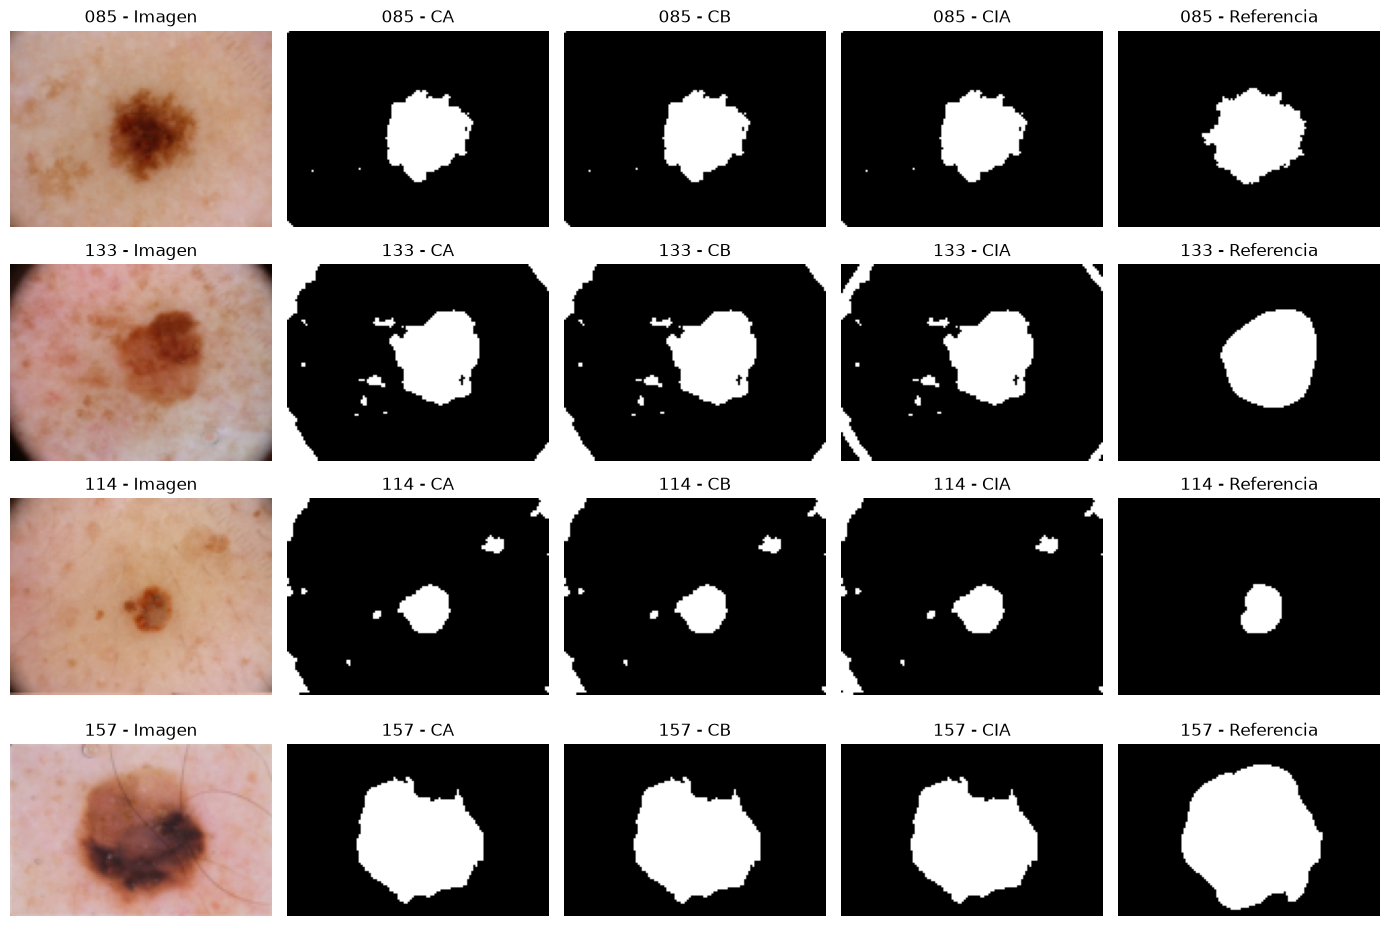

In [44]:
ejemplos = ["ISIC_0000085", "ISIC_0000133", "ISIC_0000114", "ISIC_0000157"]
fig, axes = plt.subplots(len(ejemplos), 5, figsize=(14, 2.4 * len(ejemplos)))
for fila, id_img in zip(axes, ejemplos):
    img, mascara = datos_ajuste[id_img]
    etq = etiquetas[(id_img, "M04", k_elegido.loc[id_img, "M04"])]
    paneles = [("Imagen", img)] + [(nombre, f(img, etq)) for nombre, f in CRITERIOS.items()] + [("Referencia", mascara)]
    for ax, (titulo, panel) in zip(fila, paneles):
        ax.imshow(panel, cmap=None if panel.ndim == 3 else "gray")
        ax.set_title(f"{id_img[-3:]} - {titulo}")
        ax.axis("off")
plt.tight_layout()
plt.show()

**Hallazgos.** Con λ/β = 0.25 la silueta eligió dos grupos en casi todas las imágenes, y con solo dos grupos los tres criterios escogen el mismo, el oscuro, así que sus máscaras salen casi iguales; solo en 133 el criterio de la IA quita parte del borde negro del lente. Los errores visibles vienen del agrupamiento y no del criterio: en 133 el grupo oscuro incluye las esquinas negras y en 114 otras manchas cafés, y ningún criterio que elija un solo grupo puede separarlas. Los criterios solo se distinguen cuando hay más de dos grupos, lo que ocurre con más peso en la posición. La comparación con todas las razones se hace en la Actividad 4.

## <a id="actividad4"></a> Actividad 4 - Ajuste del método

### Regla de decisión

La regla para elegir la configuración final se fijó antes de calcular las métricas, para no acomodarla a lo que saliera mejor. Una configuración es una razón λ/β junto con un criterio de máscara, y K siempre es el que elige la silueta. Compiten 21 configuraciones: las diez razones con los criterios CA y CB, y la recomendación de la IA (λ/β = 0.2 con su criterio).

1. Se elige la configuración con mayor Dice medio en las 15 imágenes de ajuste.
2. Si la segunda queda a no más de dos errores estándar de la diferencia entre ambas (calculada imagen por imagen), se considera un empate y gana la que tenga menos imágenes con Dice menor que 0.5; si persiste, la de mayor V-measure medio, y luego la más simple.

Un Dice menor que 0.5 se toma como fallo grave. Como referencia se usa la máscara que marca toda la imagen como lesión, cuyo Dice es 2p / (1 + p), con p la fracción de lesión.

### Métricas de todas las configuraciones

Para cada imagen, razón, K de 2 a 8 y criterio se calcula el Dice entre la máscara estimada y la de referencia con *f1_score*, tomando la lesión como clase positiva, y el V-measure entre los grupos de K-medias y la máscara. El Dice mide si la máscara estimada coincide con la lesión; el V-measure mide si los grupos respetan la división entre lesión y piel, aunque la lesión quede repartida en varios grupos. Se calculan todos los K, y no solo el elegido, para poder relacionar K, silueta y Dice más adelante; la selección usa solo el K de la silueta. Los criterios se calculan también fuera de las 21 configuraciones (por ejemplo, el de la IA con otras razones), pero esas combinaciones solo sirven para analizar la recomendación de la IA.

In [72]:
filas = []
for (id_img, razon, k), etq in etiquetas.items():
    img, mascara = datos_ajuste[id_img]
    v = v_measure_score(mascara.ravel(), etq.ravel())
    for criterio, f in CRITERIOS.items():
        estimada = f(img, etq)
        filas.append({"imagen": id_img, "razón": razon, "K": k, "criterio": criterio,
                      "Dice": f1_score(mascara.ravel(), estimada.ravel(), zero_division=0), "V-measure": v})
metricas = pd.DataFrame(filas)
metricas["K silueta"] = metricas["K"] == metricas.apply(lambda f: k_elegido.loc[f["imagen"], f["razón"]], axis=1)
metricas["elegible"] = ((metricas["razón"] != "IAG") & (metricas["criterio"] != "CIA")) | \
                       ((metricas["razón"] == "IAG") & (metricas["criterio"] == "CIA"))

linea_base = {i: 2 * m.mean() / (1 + m.mean()) for i, (_, m) in datos_ajuste.items()}
print("Filas:", len(metricas), "| Dice medio de la línea base (todo es lesión):", round(np.mean(list(linea_base.values())), 3))

Filas: 3465 | Dice medio de la línea base (todo es lesión): 0.351


### Selección de la configuración

Se ordenan las 21 configuraciones por Dice medio con el K de la silueta y se aplica la regla. El error estándar de la diferencia se calcula con las diferencias de Dice imagen por imagen entre la mejor configuración y cada una de las demás, porque todas se evalúan sobre las mismas 15 imágenes. Para el último desempate, que la regla dejó como "la más simple", se considera más simple el criterio CA que el CB y una razón λ/β menor; en este caso no llegó a usarse.

In [73]:
sel = metricas[metricas["K silueta"] & metricas["elegible"]]
dice_por_imagen = sel.pivot_table(index="imagen", columns=["razón", "criterio"], values="Dice")

ranking = sel.groupby(["razón", "criterio"]).agg(**{
    "Dice medio": ("Dice", "mean"), "desv.": ("Dice", "std"),
    "fallos (Dice < 0.5)": ("Dice", lambda d: (d < 0.5).sum()), "V-measure medio": ("V-measure", "mean"),
}).sort_values("Dice medio", ascending=False)

primera = ranking.index[0]
diferencias = dice_por_imagen[[primera]].values - dice_por_imagen
ranking["diferencia con la 1.ª"] = diferencias.mean()
ranking["2 errores estándar"] = 2 * diferencias.std(ddof=1) / np.sqrt(len(dice_por_imagen))
ranking["empata con la 1.ª"] = ranking["diferencia con la 1.ª"] <= ranking["2 errores estándar"]
display(ranking.round(3))

# Desempate: menos fallos, mayor V-measure, y luego la más simple (CA antes que CB, menor lambda/beta)
empatadas = ranking[ranking["empata con la 1.ª"]].reset_index()
empatadas["razón lambda/beta"] = empatadas["razón"].map(lambda r: tabla_combinaciones["lambda/beta"].get(r, 0.2))
empatadas = empatadas.sort_values(["fallos (Dice < 0.5)", "V-measure medio", "criterio", "razón lambda/beta"],
                                  ascending=[True, False, True, True])
ganadora = empatadas.iloc[0]
CONFIG_FINAL = {"razón": ganadora["razón"], "beta": RAZONES[ganadora["razón"]][0],
                "lambda": RAZONES[ganadora["razón"]][1], "criterio": ganadora["criterio"]}
print("Configuraciones empatadas con la primera:", len(empatadas))
print("Configuración final:", CONFIG_FINAL)
v_por_k = metricas.query("`razón` == 'M01' and criterio == 'CA'").groupby("K")["V-measure"].mean()
print("V-measure medio de solo color según K:", v_por_k.round(3).to_dict())

Dice medio  desv.  fallos (Dice < 0.5)  V-measure medio  \
razón criterio                                                            
M06   CB             0.864  0.067                    0            0.366   
M05   CB             0.861  0.077                    0            0.528   
      CA             0.861  0.077                    0            0.528   
IAG   CIA            0.856  0.100                    0            0.618   
M04   CA             0.853  0.103                    0            0.615   
      CB             0.853  0.103                    0            0.615   
M01   CB             0.848  0.101                    0            0.646   
      CA             0.848  0.101                    0            0.646   
M03   CB             0.848  0.101                    0            0.645   
      CA             0.848  0.101                    0            0.645   
M02   CB             0.848  0.101                    0            0.645   
      CA             0.848  0.101                    0            0.645   
M07   CB             0.830  0.134                    1            0.303   
M06   CA             0.805  0.233                    1            0.366   
M07   CA             0.770  0.251                    2            0.303   
M08   CA             0.735  0.265                    2            0.269   
      CB             0.735  0.265                    2            0.269   
M09   CA             0.566  0.305                    6            0.166   
      CB             0.566  0.305                    6            0.166   
M10   CA             0.261  0.108                   15            0.013   
      CB             0.261  0.108                   15            0.013   

                diferencia con la 1.ª  2 errores estándar  empata con la 1.ª  
razón criterio                                                                
M06   CB                        0.000               0.000               True  
M05   CB                        0.003               0.028               True  
      CA                        0.003               0.028               True  
IAG   CIA                       0.008               0.041               True  
M04   CA                        0.011               0.043               True  
      CB                        0.011               0.043               True  
M01   CB                        0.015               0.037               True  
      CA                        0.015               0.037               True  
M03   CB                        0.016               0.037               True  
      CA                        0.016               0.037               True  
M02   CB                        0.016               0.037               True  
      CA                        0.016               0.037               True  
M07   CB                        0.034               0.050               True  
M06   CA                        0.058               0.117               True  
M07   CA                        0.094               0.122               True  
M08   CA                        0.129               0.120              False  
      CB                        0.129               0.120              False  
M09   CA                        0.297               0.142              False  
      CB                        0.297               0.142              False  
M10   CA                        0.603               0.056              False  
      CB                        0.603               0.056              False

Configuraciones empatadas con la primera: 15
Configuración final: {'razón': 'M01', 'beta': 1, 'lambda': 0, 'criterio': 'CA'}
V-measure medio de solo color según K: {2: 0.646, 3: 0.531, 4: 0.438, 5: 0.4, 6: 0.377, 7: 0.353, 8: 0.34}


### Evaluación de la recomendación de la IA

Antes de calcular cualquier métrica se dejó por escrito qué significaría que la recomendación de la IA (λ/β = 0.2 con su criterio) funcionó: (i) que su Dice medio quede a menos de dos errores estándar de la mejor configuración, o que sea la mejor; (ii) que supere a la máscara que marca toda la imagen como lesión y a la configuración de solo posición; y (iii) que no tenga más imágenes con Dice menor que 0.5 que la configuración final. También se registraron sus predicciones, que aquí se contrastan: el orden en que esperaba que rindieran las razones, que la silueta elegiría dos grupos con solo color aunque K = 4 funcionaría mejor, que con solo posición su criterio caería en el respaldo, y que sus umbrales serían sensibles.

In [74]:
iag = ranking.loc[("IAG", "CIA")]
final = ranking.loc[(CONFIG_FINAL["razón"], CONFIG_FINAL["criterio"])]
dice_iag = dice_por_imagen[("IAG", "CIA")]
solo_posicion = dice_por_imagen[("M10", "CA")]
condiciones = pd.Series({
    "(i) a menos de 2 errores estándar de la mejor": bool(iag["empata con la 1.ª"]),
    "(ii) supera a todo es lesión": bool((dice_iag.mean() > np.mean(list(linea_base.values())))),
    "(ii) supera a solo posición": bool(dice_iag.mean() > solo_posicion.mean()),
    "(iii) no tiene más fallos que la final": bool(iag["fallos (Dice < 0.5)"] <= final["fallos (Dice < 0.5)"]),
})
display(condiciones.to_frame("se cumple"))

# Orden predicho por la IA para las razones que comparten ambas mallas (1 = mejor, empates promediados)
orden_ia = pd.Series({"M03": 1.5, "IAG": 1.5, "M02": 3, "M01": 4.5, "M05": 4.5, "M07": 6, "M08": 7, "M10": 8})
dice_cia = metricas[metricas["K silueta"] & (metricas["criterio"] == "CIA")].groupby("razón")["Dice"].mean()
orden_real = dice_cia[orden_ia.index].rank(ascending=False)
print("Correlación de Spearman entre el orden predicho y el observado:", round(orden_ia.corr(orden_real, method="spearman"), 2))

k_fijo = metricas[(metricas["razón"] == "IAG") & (metricas["criterio"] == "CIA")].groupby("K")["Dice"].mean()
print("Dice medio con lambda/beta = 0.2 y K fijo:", k_fijo.round(3).to_dict())

respaldos = [criterio_cia(datos_ajuste[i][0], etiquetas[(i, "M10", k_elegido.loc[i, "M10"])], informar=True)[1] for i in IDS_AJUSTE]
print("Imágenes en las que el criterio de la IA usó el respaldo con solo posición:", sum(respaldos), "de", len(respaldos))

sensibilidad = {}
for umbral_s, umbral_d in [(0.3, 0.08), (0.4, 0.08), (0.5, 0.08), (0.4, 0.05), (0.4, 0.12)]:
    dices = [dice(criterio_cia(datos_ajuste[i][0], etiquetas[(i, "IAG", k_elegido.loc[i, "IAG"])], umbral_s, umbral_d),
                  datos_ajuste[i][1]) for i in IDS_AJUSTE]
    sensibilidad[f"S >= {umbral_s} max, d >= {umbral_d}"] = np.mean(dices)
pd.Series(sensibilidad).round(3).to_frame("Dice medio")

,se cumple
(i) a menos de 2 errores estándar de la mejor,True
(ii) supera a todo es lesión,True
(ii) supera a solo posición,True
(iii) no tiene más fallos que la final,True


Correlación de Spearman entre el orden predicho y el observado: 0.7
Dice medio con lambda/beta = 0.2 y K fijo: {2: 0.812, 3: 0.849, 4: 0.848, 5: 0.865, 6: 0.827, 7: 0.812, 8: 0.845}
Imágenes en las que el criterio de la IA usó el respaldo con solo posición: 7 de 15


,Dice medio
"S >= 0.3 max, d >= 0.08",0.856
"S >= 0.4 max, d >= 0.08",0.856
"S >= 0.5 max, d >= 0.08",0.856
"S >= 0.4 max, d >= 0.05",0.856
"S >= 0.4 max, d >= 0.12",0.856


**Hallazgos.** Quince de las 21 configuraciones quedan a no más de dos errores estándar de la mejor (λ/β = 0.75 con CB, Dice medio de 0.864), así que con 15 imágenes no se puede afirmar que alguna sea mejor que las demás. Entre las empatadas ninguna tiene fallos graves, y el desempate por V-measure favorece a la de solo color (0.646), cuyos grupos separan mejor la lesión de la piel. Hay que tener en cuenta que el V-measure favorece a las agrupaciones con pocos grupos (con solo color baja de 0.646 con K = 2 a 0.340 con K = 8), así que en la práctica este desempate prefiere dos grupos con color dominante. Entre CA y CB, que con dos grupos dan la misma máscara, se queda CA. La configuración final es entonces solo color con el grupo más oscuro, con un Dice medio de 0.848. En estas imágenes la posición aporta poco porque las lesiones están centradas y tienen buen contraste, aunque sin posición nada impide que unas esquinas oscuras queden junto a la lesión, como pasó en 133.

La recomendación de la IA cumplió las tres condiciones fijadas antes de evaluarla: su Dice medio (0.856) empata con el de la mejor configuración, supera a la máscara que marca toda la imagen como lesión (0.351) y a la de solo posición (0.261), y no tiene fallos graves. Sus predicciones acertaron a medias. El orden de las razones tuvo una correlación de 0.70 con el observado, con la de solo posición como la peor pero sin que 0.2 fuera la mejor; la silueta sí eligió dos grupos con solo color en las 15 imágenes y K = 4 sí rindió mejor que K = 2 (0.848 frente a 0.812), aunque el mejor K fijo fue 5. En cambio, con solo posición su criterio usó el respaldo en 7 de 15 imágenes y no en casi todas, y sus umbrales no resultaron sensibles: con dos grupos solo hay un candidato y los umbrales no cambian la decisión.

### Grupos obtenidos en las configuraciones principales

Se muestran la imagen y los grupos de K-medias en las 15 imágenes de ajuste para las dos configuraciones con mayor Dice medio, la de solo color (que además es la final) y la de solo posición. Cada color es un grupo y el contorno amarillo es la lesión de referencia.

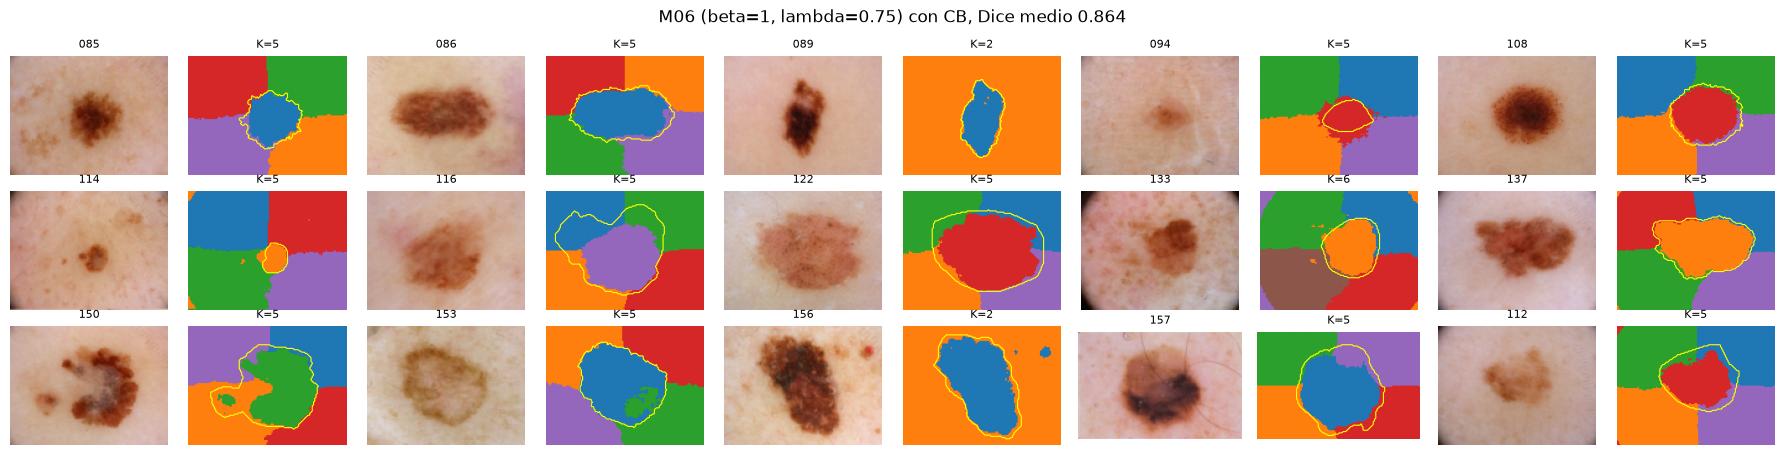

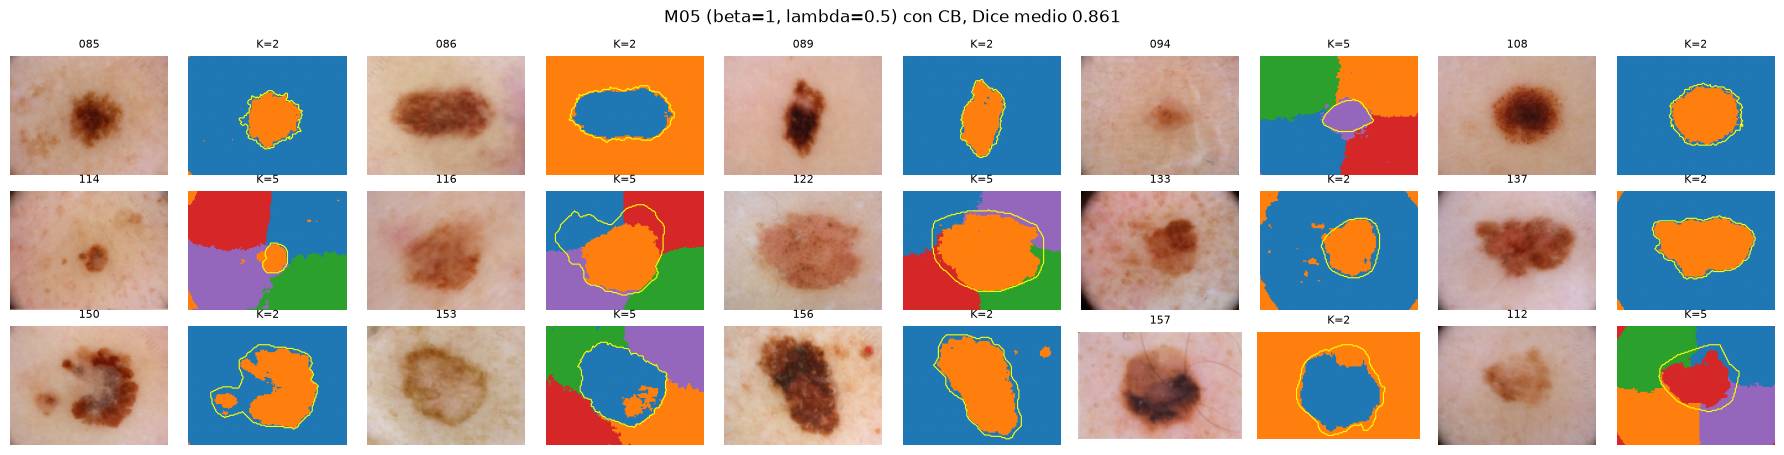

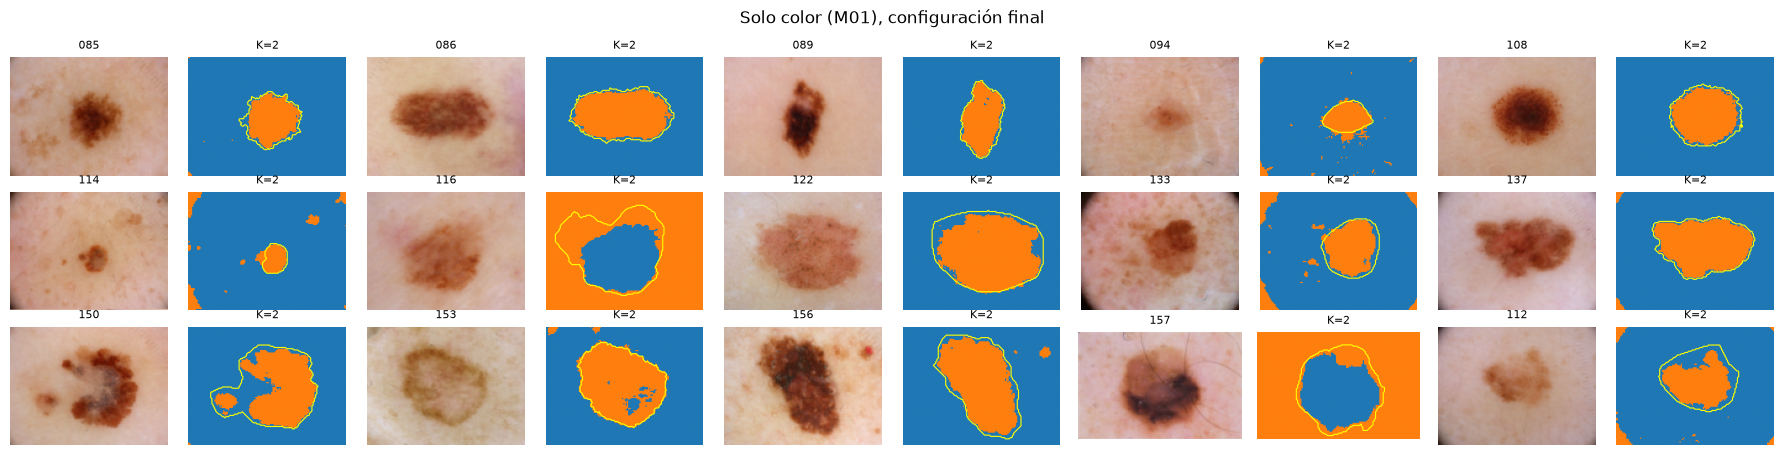

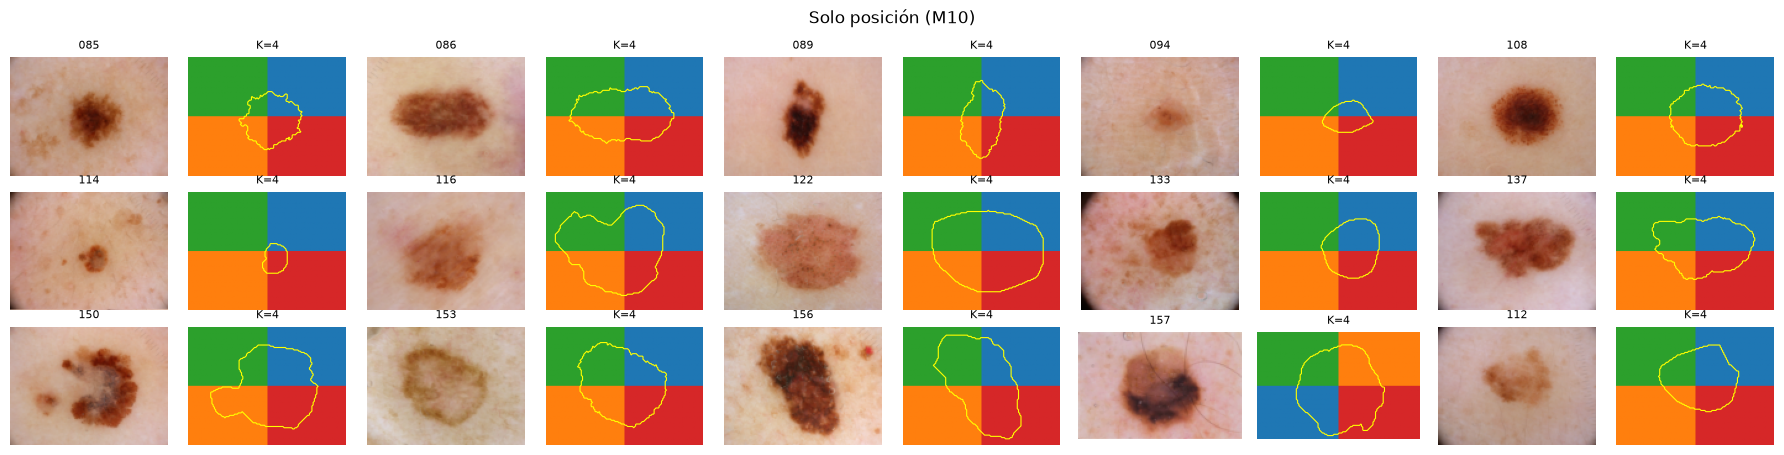

In [75]:
def mostrar_grupos(razon, titulo):
    fig, axes = plt.subplots(3, 10, figsize=(18, 4.6))
    for i, id_img in enumerate(IDS_AJUSTE):
        img, mascara = datos_ajuste[id_img]
        k = k_elegido.loc[id_img, razon]
        ax_img, ax_grp = axes[i // 5, (i % 5) * 2], axes[i // 5, (i % 5) * 2 + 1]
        ax_img.imshow(img)
        ax_grp.imshow(etiquetas[(id_img, razon, k)], cmap="tab10", vmin=0, vmax=9)
        ax_grp.contour(mascara, levels=[0.5], colors="yellow", linewidths=0.8)
        ax_img.set_title(id_img[-3:], fontsize=8)
        ax_grp.set_title(f"K={k}", fontsize=8)
        ax_img.axis("off")
        ax_grp.axis("off")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()

dos_mejores = ranking.index[:2]  # cada una es (razón, criterio)
for razon, criterio in dos_mejores:
    b, l = RAZONES[razon]
    mostrar_grupos(razon, f"{razon} (beta={b}, lambda={l}) con {criterio}, Dice medio {ranking.loc[(razon, criterio), 'Dice medio']:.3f}")
mostrar_grupos("M01", "Solo color (M01), configuración final")
mostrar_grupos("M10", "Solo posición (M10)")

### Casos de fallo de la configuración final

Se ordena el Dice por imagen de la configuración final, de peor a mejor, junto con la precisión y el recall de la máscara estimada, para ver si los errores vienen de marcar piel como lesión (baja precisión) o de dejar lesión por fuera (bajo recall).

In [76]:
filas = []
for id_img in IDS_AJUSTE:
    img, mascara = datos_ajuste[id_img]
    k = k_elegido.loc[id_img, CONFIG_FINAL["razón"]]
    estimada = CRITERIOS[CONFIG_FINAL["criterio"]](img, etiquetas[(id_img, CONFIG_FINAL["razón"], k)])
    filas.append({"imagen": id_img, "K": k,
                  "Dice": f1_score(mascara.ravel(), estimada.ravel()),
                  "precisión": precision_score(mascara.ravel(), estimada.ravel()),
                  "recall": recall_score(mascara.ravel(), estimada.ravel()),
                  "% estimado / % real": estimada.mean() / mascara.mean()})
fallos_final = pd.DataFrame(filas).set_index("imagen").sort_values("Dice")
fallos_final.round(3)

,K,Dice,precisión,recall,% estimado / % real
imagen,,,,,
ISIC_0000114,2,0.595,0.437,0.932,2.135
ISIC_0000112,2,0.741,0.873,0.644,0.737
ISIC_0000133,2,0.744,0.688,0.810,1.178
ISIC_0000116,2,0.759,0.999,0.612,0.612
ISIC_0000094,2,0.820,0.707,0.975,1.380
ISIC_0000150,2,0.823,0.999,0.701,0.702
ISIC_0000157,2,0.856,1.000,0.748,0.748
ISIC_0000122,2,0.905,0.991,0.832,0.839
ISIC_0000085,2,0.907,0.993,0.834,0.840


**Hallazgos.** La configuración final tiende a quedarse corta: en la mayoría de imágenes su precisión es cercana a 1 pero su recall está entre 0.61 y 0.95, porque con dos grupos el grupo oscuro toma el núcleo de la lesión y deja con la piel sus bordes más claros, que las máscaras de referencia sí incluyen. Es lo que pasa en 116, donde solo se toma la parte oscura (recall de 0.61), y en 112, cuya lesión es clara. El error opuesto aparece cuando hay otras zonas oscuras: en 114 la máscara marca más del doble del área real porque incluye otras manchas cafés (precisión de 0.44), y en 133 incluye parte de las esquinas negras del lente. Son los casos que la exploración ya señalaba como difíciles.

### Configuración final

Con esto queda fijada la configuración que se aplicará, sin ningún cambio, a las cinco imágenes de prueba: solo color (β = 1, λ = 0), K elegido en cada imagen por silueta entre 2 y 8, y el grupo más oscuro como lesión, con las imágenes reducidas a 128 píxeles de lado mayor y una muestra de 3000 píxeles con semilla 42 para la silueta. A partir de aquí no se modifica nada del método.

In [77]:
CONFIG_FINAL.update({"K": "silueta entre 2 y 8", "lado": LADO, "muestra silueta": MUESTRA, "semilla": SEMILLA})
pd.Series(CONFIG_FINAL).to_frame("configuración final")

,configuración final
razón,M01
beta,1
lambda,0
criterio,CA
K,silueta entre 2 y 8
lado,128
muestra silueta,3000
semilla,42


## <a id="actividad5"></a> Actividad 5 - Evaluación en las imágenes de prueba

### Método final en una sola función

La función *segmentar* aplica la configuración final tal como quedó fijada: agrupa con K de 2 a 8, elige K por silueta y toma el grupo más oscuro. Antes de usarla con la prueba se comprueba que en dos imágenes de ajuste produce las mismas máscaras que se calcularon antes, para asegurar que ajuste y prueba se tratan exactamente igual.

In [78]:
def segmentar(img, config=CONFIG_FINAL):
    beta, lam = config["beta"], config["lambda"]
    X = PesosBetaLambda(beta, lam).transform(imagen_a_matriz(img))
    etiquetas_por_k = {k: agrupar(img, beta, lam, k) for k in VALORES_K}
    k, siluetas_k = k_por_silueta(X, etiquetas_por_k, indices_muestra(len(X)))
    mascara = CRITERIOS[config["criterio"]](img, etiquetas_por_k[k])
    return mascara, etiquetas_por_k[k], k, siluetas_k[k]

for id_img in ["ISIC_0000085", "ISIC_0000133"]:
    img = datos_ajuste[id_img][0]
    nueva, _, k, _ = segmentar(img)
    anterior = criterio_ca(img, etiquetas[(id_img, "M01", k_elegido.loc[id_img, "M01"])])
    print(f"{id_img}: K = {k} | misma máscara que en el ajuste: {np.array_equal(nueva, anterior)}")

ISIC_0000085: K = 2 | misma máscara que en el ajuste: True
ISIC_0000133: K = 2 | misma máscara que en el ajuste: True


### Resultados en prueba

Aquí se abren por primera vez las cinco imágenes de prueba y sus máscaras. Se reducen igual que las de ajuste y se les aplica *segmentar* sin ningún cambio. Para cada imagen se reportan el K elegido, la silueta, el Dice, el V-measure, la precisión y el recall, con la lesión como clase positiva.

In [79]:
datos_prueba = {i: reducir(*cargar(i), LADO) for i in IDS_PRUEBA}

filas, mascaras_prueba = [], {}
for id_img, (img, mascara) in datos_prueba.items():
    estimada, etq, k, silueta = segmentar(img)
    mascaras_prueba[id_img] = estimada
    ref, est = mascara.ravel(), estimada.ravel()
    filas.append({"imagen": id_img, "K": k, "silueta": silueta, "Dice": f1_score(ref, est),
                  "V-measure": v_measure_score(ref, etq.ravel()),
                  "precisión": precision_score(ref, est), "recall": recall_score(ref, est)})
resultados_prueba = pd.DataFrame(filas).set_index("imagen")
resultados_prueba.round(3)

,K,silueta,Dice,V-measure,precisión,recall
imagen,,,,,,
ISIC_0000087,2,0.745,0.880,0.637,0.997,0.788
ISIC_0000105,2,0.821,0.898,0.752,0.946,0.854
ISIC_0000110,2,0.738,0.629,0.321,0.650,0.610
ISIC_0000123,2,0.738,0.898,0.694,0.847,0.956
ISIC_0000128,2,0.824,0.935,0.821,1.000,0.877


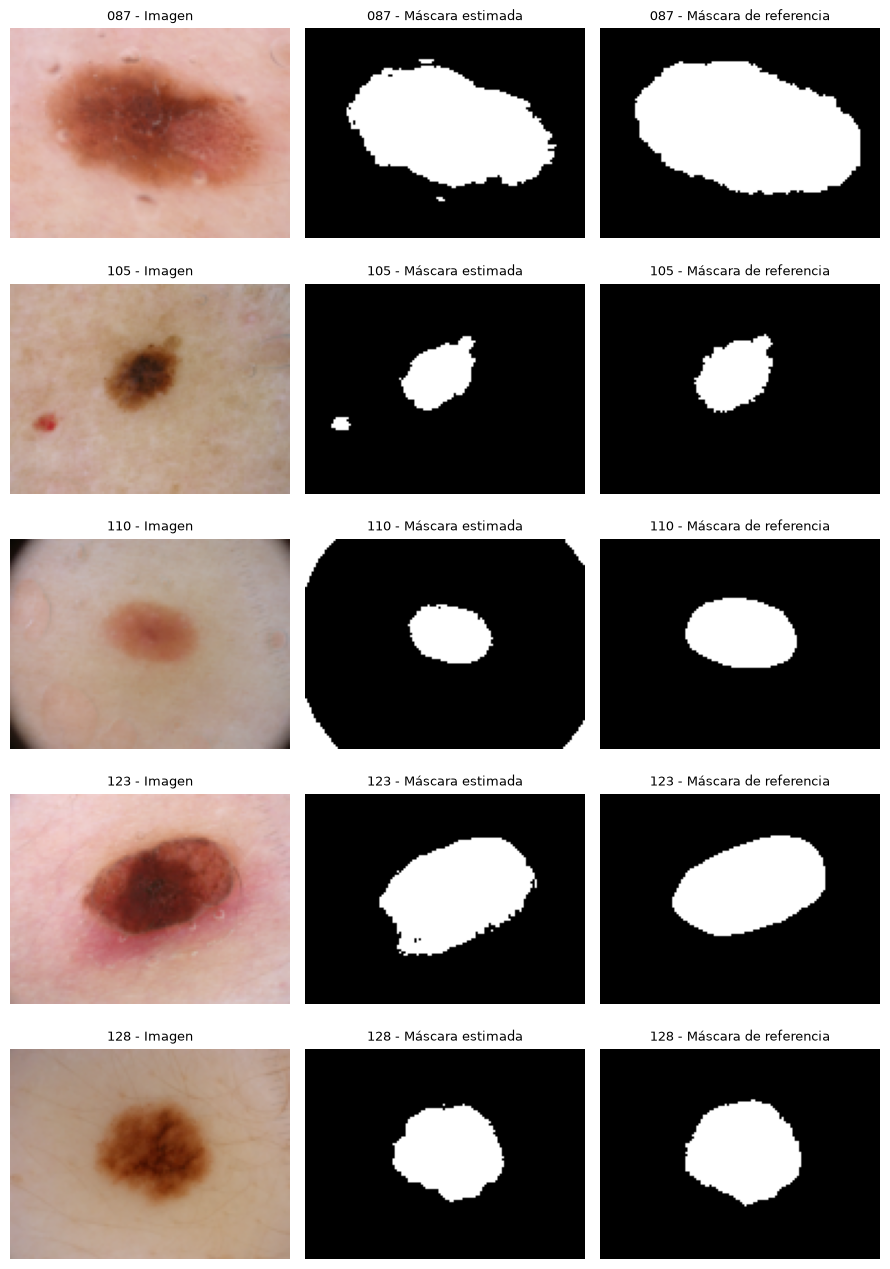

In [80]:
fig, axes = plt.subplots(len(IDS_PRUEBA), 3, figsize=(9, 2.6 * len(IDS_PRUEBA)))
for fila, id_img in zip(axes, IDS_PRUEBA):
    img, mascara = datos_prueba[id_img]
    for ax, (titulo, panel) in zip(fila, [("Imagen", img), ("Máscara estimada", mascaras_prueba[id_img]), ("Máscara de referencia", mascara)]):
        ax.imshow(panel, cmap=None if panel.ndim == 3 else "gray")
        ax.set_title(f"{id_img[-3:]} - {titulo}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

### Ajuste frente a prueba

Se compara el Dice medio de la configuración final en las 15 imágenes de ajuste y en las 5 de prueba, junto con su variación entre imágenes.

In [81]:
comparacion = pd.DataFrame({
    "ajuste (15)": fallos_final[["Dice", "precisión", "recall"]].agg(["mean", "std", "min"]).stack(),
    "prueba (5)": resultados_prueba[["Dice", "precisión", "recall"]].agg(["mean", "std", "min"]).stack(),
}).unstack(0).swaplevel(axis=1).sort_index(axis=1)
comparacion.round(3)

mean                    min                    std           
          ajuste (15) prueba (5) ajuste (15) prueba (5) ajuste (15) prueba (5)
Dice            0.848      0.848       0.595      0.629       0.101      0.124
precisión       0.904      0.888       0.437      0.650       0.166      0.147
recall          0.827      0.817       0.612      0.610       0.109      0.130